# Real-time forecasting results (IEP data)

Produced by `python -m pipelines.run_realtime` (see `forecasting/pipeline.py`).

* **Backtest**: pseudo real-time, last 12 quarters with known GDP, horizons 1-8 quarters
  (h = 1 is the nowcast of the current quarter). Every forecast uses only data known at its origin;
  models are re-estimated every `RT_REFIT_EVERY` quarters on an expanding window.
* **Grid**: models GB / NGB / TabNet / DFM x train start (2000, 2010) x variable set (short, medium, all)
  x features (classic d12, rolling means) x data availability (1-3 months of the quarter).
* **Metric**: RMSE of the y/y log growth; `rel_rmse_naive` < 1 means better than the naive forecast
  (last known y/y growth).

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, str(Path.cwd()))

import config
from forecasting.dataset import DatasetBuilder, target_column
from forecasting.report import RunResults

RESULTS_DIR = config.RT_RESULTS_DIR  # folder with runs/
RUN = None  # None -> latest finished run, or e.g. "2026-10-22"

run = RunResults.latest(RESULTS_DIR) if RUN is None else RunResults(Path(RESULTS_DIR) / "runs" / RUN)
metrics = run.metrics

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_tbl_cols(20)

MODEL_COLORS = {"gb": "#2a78d6", "ngb": "#eb6834", "tabnet": "#1baf7a", "dfm": "#eda100"}
NEUTRAL, INK = "#a9a8a2", "#4b4a45"
TARGETS = ["gdp", "cons", "inv", "inv_cap"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": NEUTRAL, "axes.labelcolor": INK, "xtick.color": "#6b6a64", "ytick.color": "#6b6a64",
    "lines.linewidth": 1.8,
})
info = run.info
print(f"run {info['run_id']} created {info['created']}")
print(f"targets known up to {info['last_known_quarter']}, monthly data up to quarter {info['last_data_quarter']}")
print(f"models: {info['models']}, specifications evaluated: {metrics.select(*['model','train_start','var_set','features_type','availability','target','horizon']).unique().height}")
if run.failed_specs is not None:
    print(f"failed specifications: {run.failed_specs.height}")

run 2026-10-22 created 2026-10-22T00:50:37
targets known up to 2026-04-01, monthly data up to quarter 2026-07-01
models: ['gb', 'ngb', 'dfm', 'tabnet'], specifications evaluated: 4608


## 1. Best achievable accuracy by horizon

For every model the best specification at each horizon (lowest RMSE). Dashed line = naive forecast.

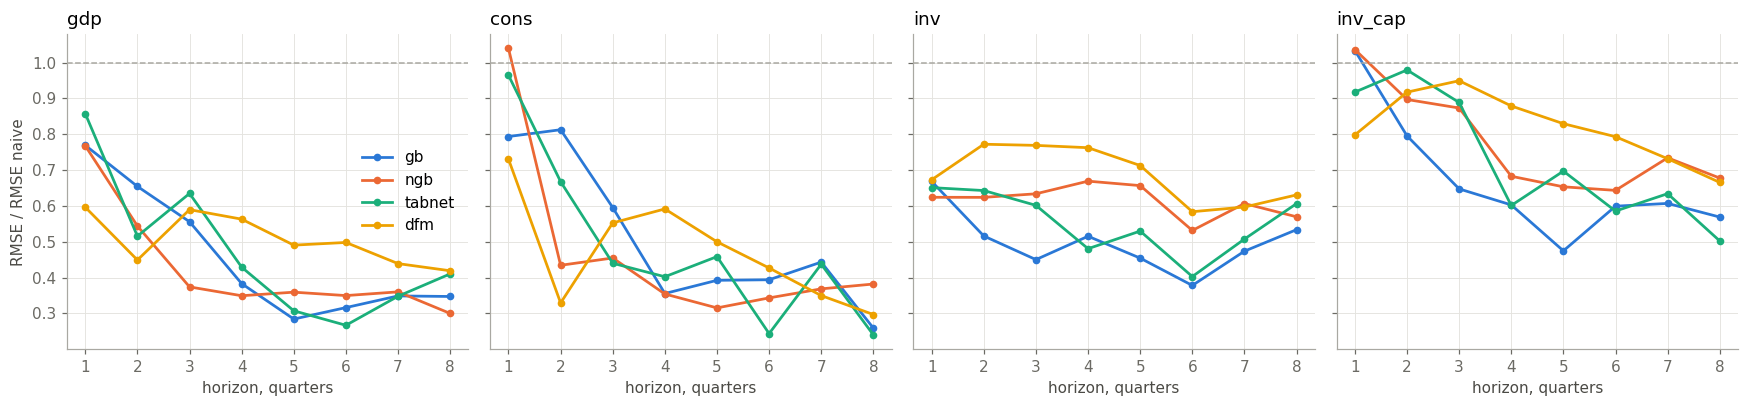

In [2]:
best_by_model = run.best_by_model()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, target in zip(axes, TARGETS):
    part = best_by_model.filter(pl.col("target") == target)
    for model, color in MODEL_COLORS.items():
        s = part.filter(pl.col("model") == model).sort("horizon")
        if s.height:
            ax.plot(s["horizon"], s["rel_rmse_naive"], color=color, marker="o", markersize=4, label=model)
    ax.axhline(1, color=NEUTRAL, linestyle="--", linewidth=1)
    ax.set_title(target, loc="left")
    ax.set_xlabel("horizon, quarters")
axes[0].set_ylabel("RMSE / RMSE naive")
axes[0].legend(frameon=False)
fig.tight_layout()

In [3]:
best_by_model.pivot(on="model", index=["target", "horizon"], values="rmse").sort(["target", "horizon"])

target,horizon,dfm,gb,ngb,tabnet
str,i64,f64,f64,f64,f64
"""cons""",1,0.009054,0.009839,0.012884,0.011957
"""cons""",2,0.011722,0.028923,0.01546,0.023767
"""cons""",3,0.030365,0.032717,0.024985,0.024176
"""cons""",4,0.041421,0.024897,0.024802,0.028174
"""cons""",5,0.039846,0.03128,0.025143,0.036551
"""cons""",6,0.032599,0.030092,0.026226,0.018619
"""cons""",7,0.025495,0.032302,0.026862,0.031875
"""cons""",8,0.020172,0.0176,0.025949,0.016314
"""gdp""",1,0.008337,0.010753,0.010734,0.011985


## 2. Share of specifications better than naive

In [4]:
run.share_beating_naive().pivot(on="model", index="target", values="share_specs_better_than_naive")

target,dfm,gb,ngb,tabnet
str,f64,f64,f64,f64
"""cons""",0.819444,0.75,0.809028,0.666667
"""gdp""",0.96875,0.881944,0.857639,0.746528
"""inv""",0.982639,0.982639,0.982639,0.84375
"""inv_cap""",0.673611,0.701389,0.621528,0.569444


## 3. What matters: effect of each design choice

Median `rel_rmse_naive` over all other choices (lower is better).

In [5]:
for factor in ["train_start", "var_set", "features_type", "availability"]:
    effect = run.factor_effect(factor).pivot(on=factor, index=["target", "model"], values="median_rel_rmse").sort(["target", "model"])
    print(f"--- {factor}")
    print(effect)

--- train_start
shape: (16, 4)
┌─────────┬────────┬──────────┬──────────┐
│ target  ┆ model  ┆ 2000     ┆ 2010     │
│ ---     ┆ ---    ┆ ---      ┆ ---      │
│ str     ┆ str    ┆ f64      ┆ f64      │
╞═════════╪════════╪══════════╪══════════╡
│ cons    ┆ dfm    ┆ 0.648113 ┆ 0.696011 │
│ cons    ┆ gb     ┆ 0.721296 ┆ 0.741346 │
│ cons    ┆ ngb    ┆ 0.500752 ┆ 0.641459 │
│ cons    ┆ tabnet ┆ 0.668786 ┆ 0.864148 │
│ gdp     ┆ dfm    ┆ 0.658393 ┆ 0.589387 │
│ gdp     ┆ gb     ┆ 0.601353 ┆ 0.589467 │
│ gdp     ┆ ngb    ┆ 0.51132  ┆ 0.546545 │
│ gdp     ┆ tabnet ┆ 0.653314 ┆ 0.740066 │
│ inv     ┆ dfm    ┆ 0.832765 ┆ 0.781777 │
│ inv     ┆ gb     ┆ 0.713311 ┆ 0.668502 │
│ inv     ┆ ngb    ┆ 0.778365 ┆ 0.710479 │
│ inv     ┆ tabnet ┆ 0.791251 ┆ 0.723482 │
│ inv_cap ┆ dfm    ┆ 0.938014 ┆ 0.91236  │
│ inv_cap ┆ gb     ┆ 0.872097 ┆ 0.836941 │
│ inv_cap ┆ ngb    ┆ 0.868149 ┆ 0.823059 │
│ inv_cap ┆ tabnet ┆ 0.945525 ┆ 0.923448 │
└─────────┴────────┴──────────┴──────────┘
--- var_set
shape: (16,

## 4. Top specifications per target (mean relative RMSE over 8 horizons)

In [6]:
for target in TARGETS:
    print(f"--- {target}")
    print(run.top_specs(target, 10))

--- gdp
shape: (10, 8)
┌──────┬───────┬─────────────┬─────────┬───────────────┬──────────────┬───────────────┬───────────┐
│ rank ┆ model ┆ train_start ┆ var_set ┆ features_type ┆ availability ┆ mean_rel_rmse ┆ mean_rmse │
│ ---  ┆ ---   ┆ ---         ┆ ---     ┆ ---           ┆ ---          ┆ ---           ┆ ---       │
│ i64  ┆ str   ┆ i64         ┆ str     ┆ str           ┆ i64          ┆ f64           ┆ f64       │
╞══════╪═══════╪═════════════╪═════════╪═══════════════╪══════════════╪═══════════════╪═══════════╡
│ 1    ┆ ngb   ┆ 2000        ┆ all     ┆ rolling       ┆ 2            ┆ 0.522253      ┆ 0.018893  │
│ 2    ┆ ngb   ┆ 2000        ┆ medium  ┆ rolling       ┆ 1            ┆ 0.531986      ┆ 0.018839  │
│ 3    ┆ gb    ┆ 2000        ┆ all     ┆ classic       ┆ 2            ┆ 0.532913      ┆ 0.019286  │
│ 4    ┆ ngb   ┆ 2000        ┆ medium  ┆ rolling       ┆ 3            ┆ 0.534034      ┆ 0.019347  │
│ 5    ┆ ngb   ┆ 2000        ┆ all     ┆ classic       ┆ 1            ┆ 0.538

## 5. Best specification for every target, horizon and data availability

This table is what the future forecasts in section 8 use.

In [7]:
run.best.select("target", "availability", "horizon", "model", "train_start", "var_set", "features_type", "rmse", "rel_rmse_naive")

target,availability,horizon,model,train_start,var_set,features_type,rmse,rel_rmse_naive
str,i64,i64,str,i64,str,str,f64,f64
"""cons""",1,1,"""gb""",2000,"""all""","""classic""",0.010374,0.836957
"""cons""",1,2,"""dfm""",2000,"""short""","""classic""",0.016075,0.451727
"""cons""",1,3,"""tabnet""",2000,"""short""","""classic""",0.024176,0.440099
"""cons""",1,4,"""gb""",2000,"""all""","""classic""",0.024897,0.355658
"""cons""",1,5,"""ngb""",2000,"""medium""","""classic""",0.030513,0.382883
"""cons""",1,6,"""tabnet""",2000,"""short""","""classic""",0.018619,0.243821
"""cons""",1,7,"""dfm""",2000,"""medium""","""rolling""",0.025495,0.349889
"""cons""",1,8,"""tabnet""",2000,"""medium""","""rolling""",0.016314,0.240236
"""cons""",2,1,"""gb""",2000,"""short""","""classic""",0.011656,0.940383


## 6. Quality dynamics: rolling RMSE over the test period

RMSE of the last 4 test quarters, for the overall best specification of every model (rank by mean relative RMSE).

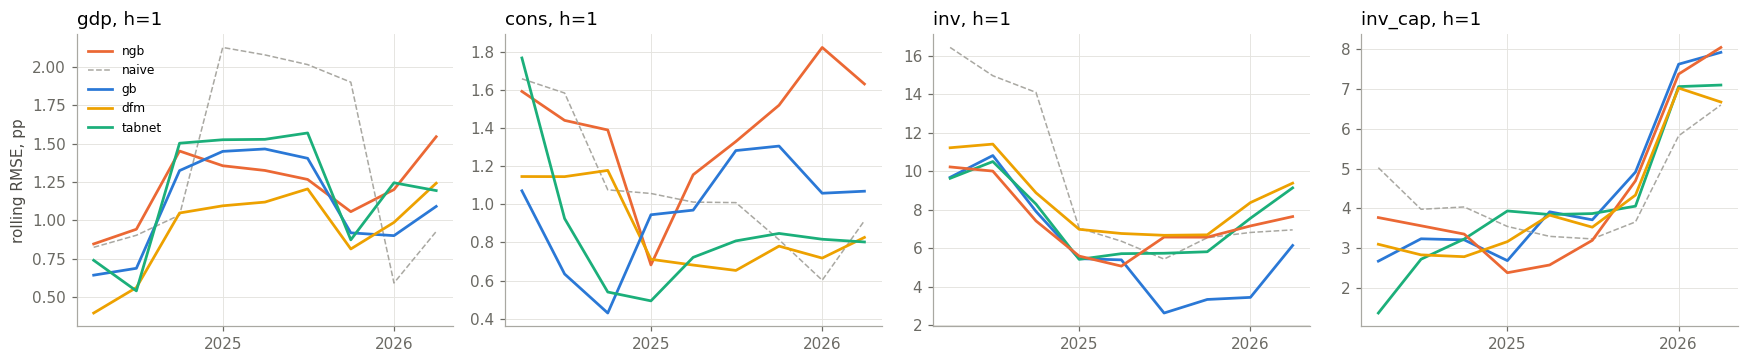

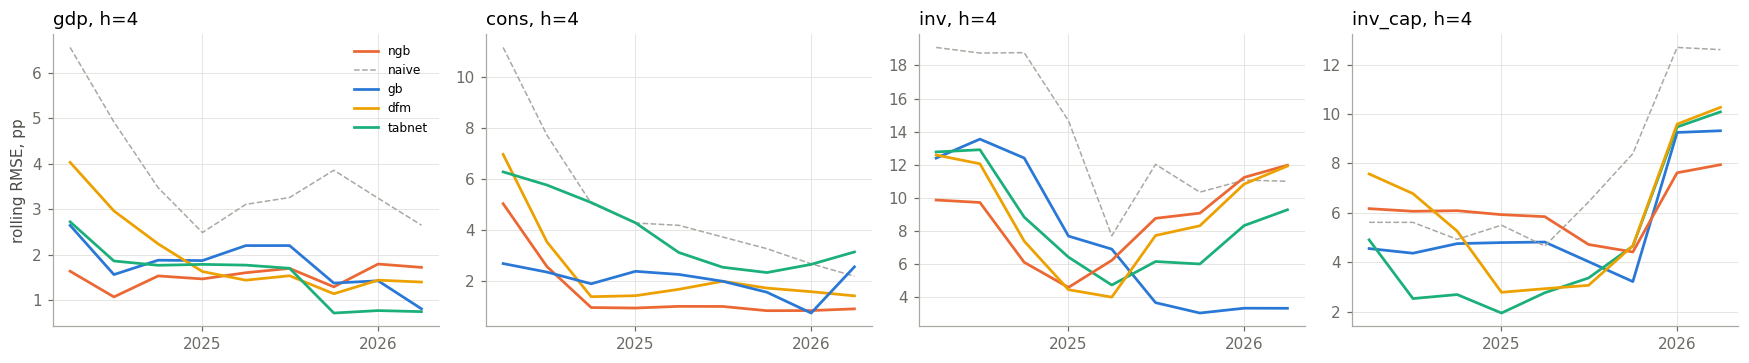

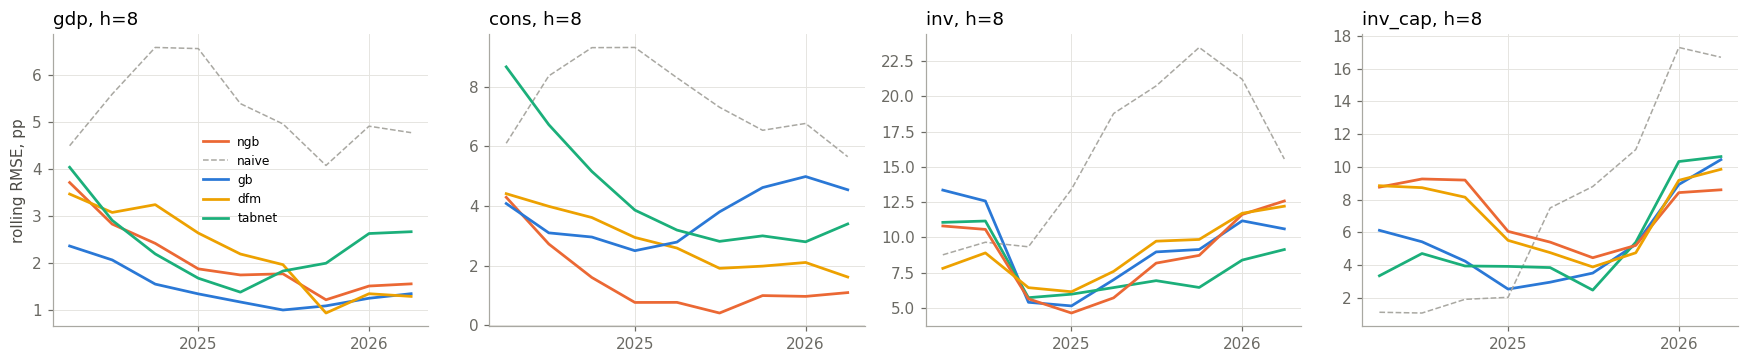

In [8]:
ranking = run.ranking
rolling = run.rolling
for horizon in (1, 4, 8):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharex=True)
    for ax, target in zip(axes, TARGETS):
        top = ranking.filter(pl.col("target") == target).sort("rank").group_by("model", maintain_order=True).first()
        for spec in top.iter_rows(named=True):
            s = rolling.join(pl.DataFrame([spec]).select(["model", "train_start", "var_set", "features_type", "availability", "target"]),
                             on=["model", "train_start", "var_set", "features_type", "availability", "target"])
            s = s.filter(pl.col("horizon") == horizon).sort("target_date")
            if s.height:
                ax.plot(s["target_date"], s["rolling_rmse"] * 100, color=MODEL_COLORS[spec["model"]], label=spec["model"])
                if spec["model"] == top["model"][0]:
                    ax.plot(s["target_date"], s["rolling_rmse_naive"] * 100, color=NEUTRAL, linestyle="--", linewidth=1, label="naive")
        ax.set_title(f"{target}, h={horizon}", loc="left")
        ax.xaxis.set_major_locator(mdates.YearLocator())
    axes[0].set_ylabel("rolling RMSE, pp")
    axes[0].legend(frameon=False, fontsize=8)
    fig.tight_layout()

## 7. Test forecasts vs facts (best specification per model, h = 1 and h = 4)

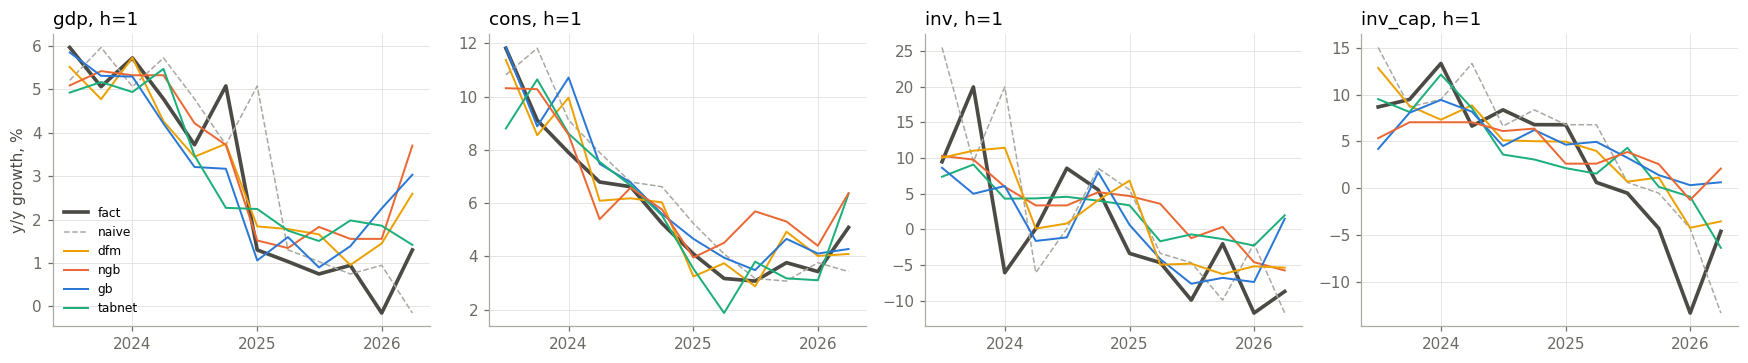

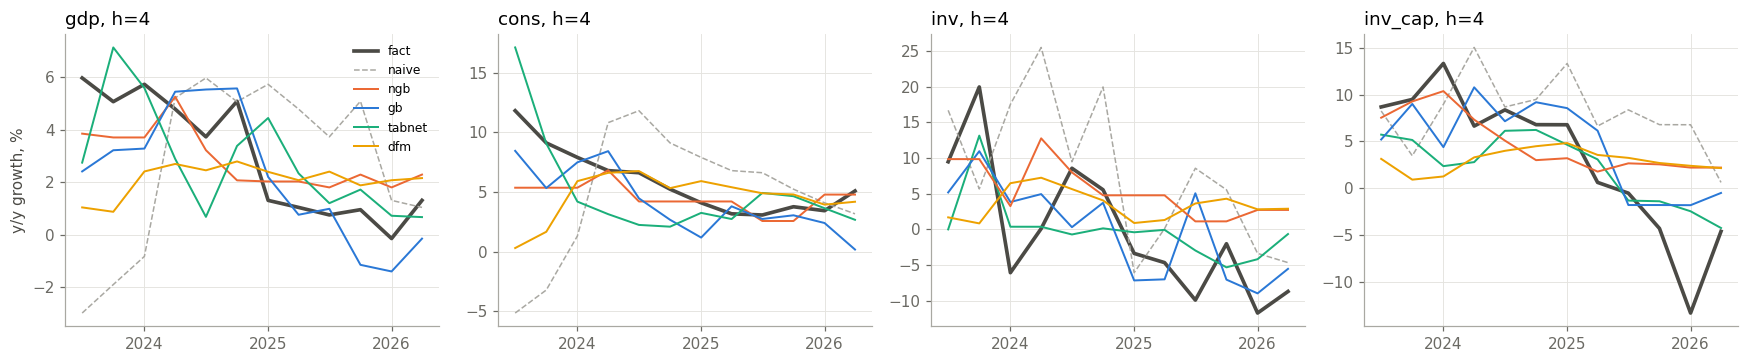

In [9]:
errors = run.errors
for horizon in (1, 4):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharex=True)
    for ax, target in zip(axes, TARGETS):
        best_h = run.metrics.filter((pl.col("target") == target) & (pl.col("horizon") == horizon)).sort("rmse").group_by("model", maintain_order=True).first()
        facts = errors.filter((pl.col("target") == target) & (pl.col("horizon") == horizon)).select("target_date", "fact", "naive").unique().sort("target_date")
        ax.plot(facts["target_date"], facts["fact"] * 100, color=INK, linewidth=2.4, label="fact")
        ax.plot(facts["target_date"], facts["naive"] * 100, color=NEUTRAL, linestyle="--", linewidth=1, label="naive")
        for spec in best_h.iter_rows(named=True):
            keys = ["model", "train_start", "var_set", "features_type", "availability", "target", "horizon"]
            s = errors.join(pl.DataFrame([{k: spec[k] for k in keys}]), on=keys).sort("target_date")
            ax.plot(s["target_date"], s["pred"] * 100, color=MODEL_COLORS[spec["model"]], linewidth=1.3, label=spec["model"])
        ax.set_title(f"{target}, h={horizon}", loc="left")
        ax.xaxis.set_major_locator(mdates.YearLocator())
    axes[0].set_ylabel("y/y growth, %")
    axes[0].legend(frameon=False, fontsize=8)
    fig.tight_layout()

## 8. Forecasts for the next 2 years

**Consensus** (thick line) = median forecast of the 10 specifications with the lowest backtest RMSE for that target, horizon and availability; dark band = their min-max range. Dashed = single best specification (fragile: with 12 test quarters the winner is often only marginally better than the runner-up). Light band = 10-90% range over all specifications. Availability = most months published for the origin quarter.

[INFO] dataset: 111 quarters 1999-01-01 -> 2026-07-01, 61 monthly variables, 732 feature columns


origin 2026-07-01, using availability 2 (months of the origin quarter published)


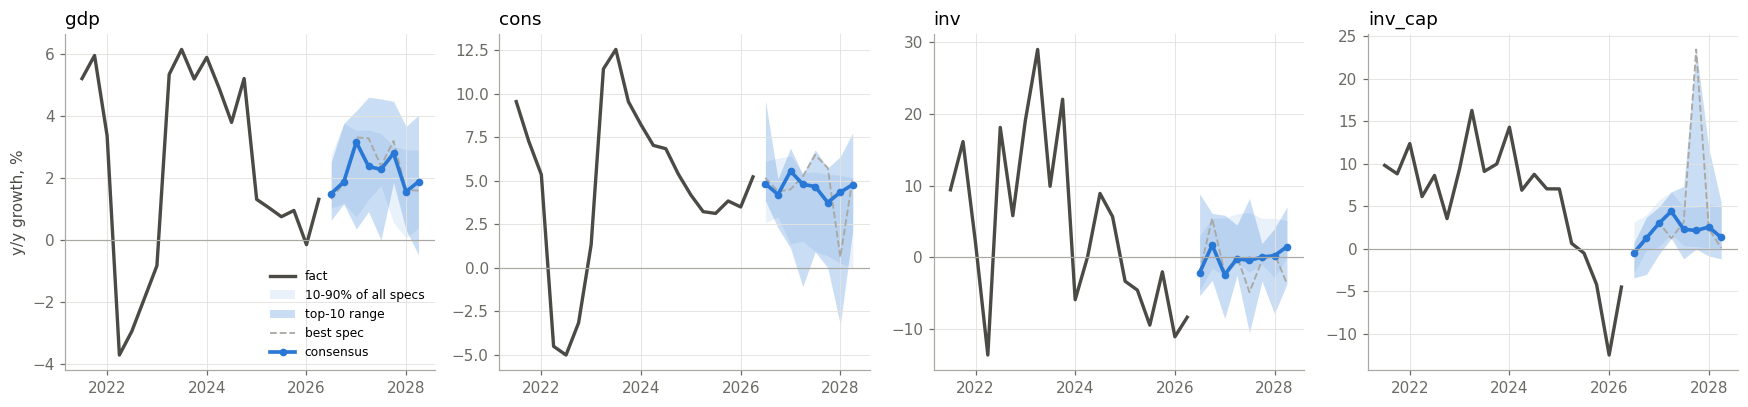

In [10]:
future = run.future
future_best = run.future_best
consensus = run.future_consensus
dataset = DatasetBuilder().build_from_iep()

# availability with the most complete data for the origin quarter
availability = (
    future.group_by("availability").agg(pl.col("origin_data_share").mean()).filter(pl.col("origin_data_share") >= 0.9)
    .sort("availability")["availability"].to_list()
)
availability = availability[-1] if availability else 1
print(f"origin {future['origin'][0]}, using availability {availability} (months of the origin quarter published)")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, target in zip(axes, TARGETS):
    history = dataset.frame.select("date", target_column(target)).drop_nulls().tail(20)
    ax.plot(history["date"], (history[target_column(target)].exp() - 1) * 100, color=INK, linewidth=2.2, label="fact")
    band = (
        future.filter((pl.col("target") == target) & (pl.col("availability") == availability))
        .group_by("target_date").agg(pl.col("pred_yoy_pct").quantile(0.1).alias("lo"), pl.col("pred_yoy_pct").quantile(0.9).alias("hi"))
        .sort("target_date")
    )
    ax.fill_between(band["target_date"], band["lo"], band["hi"], color="#2a78d6", alpha=0.10, linewidth=0, label="10-90% of all specs")
    cons = consensus.filter((pl.col("target") == target) & (pl.col("availability") == availability)).sort("target_date")
    ax.fill_between(cons["target_date"], cons["min_yoy_pct"], cons["max_yoy_pct"], color="#2a78d6", alpha=0.25, linewidth=0, label="top-10 range")
    best = future_best.filter((pl.col("target") == target) & (pl.col("availability") == availability)).sort("target_date")
    ax.plot(best["target_date"], best["pred_yoy_pct"], color=NEUTRAL, linewidth=1.2, linestyle="--", label="best spec")
    ax.plot(cons["target_date"], cons["pred_yoy_pct"], color="#2a78d6", linewidth=2.4, marker="o", markersize=4, label="consensus")
    ax.axhline(0, color=NEUTRAL, linewidth=0.8)
    ax.set_title(target, loc="left")
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
axes[0].set_ylabel("y/y growth, %")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

In [11]:
(
    consensus.filter(pl.col("availability") == availability)
    .join(future_best.select("target", "availability", "horizon", pl.col("pred_yoy_pct").alias("best_spec_yoy_pct")),
          on=["target", "availability", "horizon"])
    .select("target", "horizon", "target_date",
            pl.col("pred_yoy_pct").round(2).alias("consensus_yoy_pct"),
            pl.col("min_yoy_pct").round(2), pl.col("max_yoy_pct").round(2),
            pl.col("best_spec_yoy_pct").round(2),
            pl.col("mean_backtest_rel_rmse_naive").round(2), "models")
    .sort(["target", "horizon"])
)

target,horizon,target_date,consensus_yoy_pct,min_yoy_pct,max_yoy_pct,best_spec_yoy_pct,mean_backtest_rel_rmse_naive,models
str,i64,date,f64,f64,f64,f64,f64,str
"""cons""",1,2026-07-01,4.83,3.85,9.62,5.16,1.16,"""ngb,gb,dfm,tabnet"""
"""cons""",2,2026-10-01,4.21,2.29,5.1,4.38,0.5,"""dfm,ngb,tabnet"""
"""cons""",3,2027-01-01,5.55,1.14,6.87,4.5,0.56,"""ngb,gb,tabnet"""
"""cons""",4,2027-04-01,4.79,-1.09,5.35,5.24,0.45,"""ngb,tabnet,gb"""
"""cons""",5,2027-07-01,4.66,0.92,6.77,6.49,0.44,"""ngb,gb,tabnet"""
"""cons""",6,2027-10-01,3.75,0.0,5.73,5.73,0.48,"""ngb,tabnet,gb,dfm"""
"""cons""",7,2028-01-01,4.34,-3.28,6.38,0.61,0.46,"""ngb,dfm,gb,tabnet"""
"""cons""",8,2028-04-01,4.78,2.14,7.74,5.16,0.43,"""ngb,dfm,tabnet,gb"""
"""gdp""",1,2026-07-01,1.5,0.63,2.51,1.32,0.71,"""dfm,ngb"""


## 9. Quality across runs

Every run appends its metrics to `results/metrics_history.csv`; with several runs this shows how the accuracy of the best specifications evolves as new data arrives.

In [12]:
history_path = Path(RESULTS_DIR) / "metrics_history.csv"
history = pl.read_csv(history_path, schema_overrides={"run_id": pl.Utf8, "last_known_quarter": pl.Utf8})
(
    history.group_by(["run_id", "last_known_quarter", "model", "target"])
    .agg(pl.col("rel_rmse_naive").min().alias("best_rel_rmse"), pl.col("rel_rmse_naive").median().alias("median_rel_rmse"))
    .sort(["target", "model", "run_id"])
)

run_id,last_known_quarter,model,target,best_rel_rmse,median_rel_rmse
str,str,str,str,f64,f64
"""2026-10-22""","""2026-04-01""","""dfm""","""cons""",0.29706,0.687935
"""2026-10-22""","""2026-04-01""","""gb""","""cons""",0.259174,0.728172
"""2026-10-22""","""2026-04-01""","""ngb""","""cons""",0.315502,0.602477
"""2026-10-22""","""2026-04-01""","""tabnet""","""cons""",0.240236,0.778453
"""2026-10-22""","""2026-04-01""","""dfm""","""gdp""",0.419175,0.631277
"""2026-10-22""","""2026-04-01""","""gb""","""gdp""",0.28436,0.591513
"""2026-10-22""","""2026-04-01""","""ngb""","""gdp""",0.300083,0.519951
"""2026-10-22""","""2026-04-01""","""tabnet""","""gdp""",0.267002,0.689302
"""2026-10-22""","""2026-04-01""","""dfm""","""inv""",0.583949,0.800834
